# Lectura de los datos

Datos: https://www.kaggle.com/datamunge/sign-language-mnist

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

train = pd.read_csv('data/sign-language-mnist/sign_mnist_train.csv')
test = pd.read_csv('data/sign-language-mnist/sign_mnist_test.csv')

In [2]:
print("El conjunto de datos tiene {} filas y {} columnas".format(train.shape[0],train.shape[1]))
train.head()

El conjunto de datos tiene 27455 filas y 785 columnas


,label,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,...,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783,pixel784
0,3,107,118,127,134,139,143,146,150,153,...,207,207,207,207,206,206,206,204,203,202
1,6,155,157,156,156,156,157,156,158,158,...,69,149,128,87,94,163,175,103,135,149
2,2,187,188,188,187,187,186,187,188,187,...,202,201,200,199,198,199,198,195,194,195
3,2,211,211,212,212,211,210,211,210,210,...,235,234,233,231,230,226,225,222,229,163
4,13,164,167,170,172,176,179,180,184,185,...,92,105,105,108,133,163,157,163,164,179


In [3]:
print("El conjunto de datos tiene {} filas y {} columnas".format(test.shape[0],test.shape[1]))
test.head()

El conjunto de datos tiene 7172 filas y 785 columnas


,label,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,...,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783,pixel784
0,6,149,149,150,150,150,151,151,150,151,...,138,148,127,89,82,96,106,112,120,107
1,5,126,128,131,132,133,134,135,135,136,...,47,104,194,183,186,184,184,184,182,180
2,10,85,88,92,96,105,123,135,143,147,...,68,166,242,227,230,227,226,225,224,222
3,0,203,205,207,206,207,209,210,209,210,...,154,248,247,248,253,236,230,240,253,255
4,3,188,191,193,195,199,201,202,203,203,...,26,40,64,48,29,46,49,46,46,53


In [4]:
y_train = train.label
x_train = train.drop("label",axis=1) / 255.0
y_test = test.label
x_test = test.drop("label",axis=1) / 255.0

In [5]:
abc = [chr(65+i) for i in np.unique(y_test)]
print(abc)

['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'K', 'L', 'M', 'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'W', 'X', 'Y']


In [6]:
letters_map = dict(zip(np.unique(y_test), range(len(np.unique(y_test)))))
letters_map

{0: 0,
 1: 1,
 2: 2,
 3: 3,
 4: 4,
 5: 5,
 6: 6,
 7: 7,
 8: 8,
 10: 9,
 11: 10,
 12: 11,
 13: 12,
 14: 13,
 15: 14,
 16: 15,
 17: 16,
 18: 17,
 19: 18,
 20: 19,
 21: 20,
 22: 21,
 23: 22,
 24: 23}

In [7]:
y_train = y_train.replace(letters_map).values
y_test = y_test.replace(letters_map).values

In [8]:
x_train = x_train.values.reshape((-1,28,28,1))
x_test = x_test.values.reshape((-1,28,28,1))

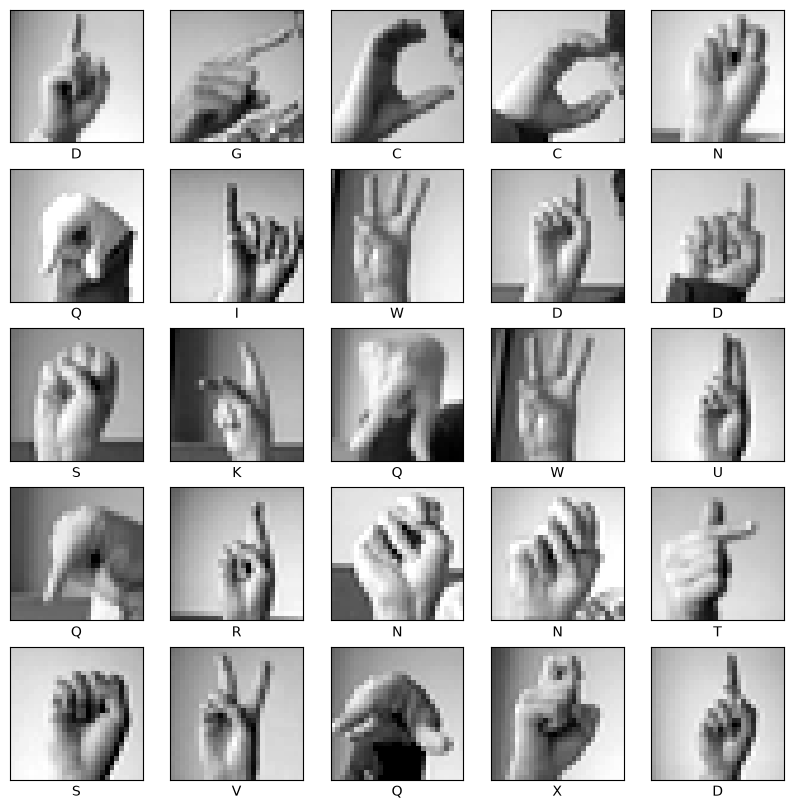

In [9]:
plt.figure(figsize=(10,10))
for i in range(25):
    plt.subplot(5,5,i+1)
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)
    number = x_train[i].reshape(28,28)
    plt.imshow(number, cmap=plt.cm.gray)
    # A la letra 65
    plt.xlabel(abc[y_train[i]])
plt.show()

# Construyendo y entrenando la NN

In [10]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import datasets, layers, models

model = models.Sequential()
model.add(layers.Conv2D(filters = 64, 
                        kernel_size = (4, 4),
                        activation='relu',
                        padding="same",
                        input_shape=(28,28,1,)))
model.add(layers.Dropout(rate = 0.4))
model.add(layers.MaxPooling2D(pool_size = (2, 2)))

model.add(layers.Conv2D(filters = 64, 
                        kernel_size = (4, 4),
                        activation='relu',
                        padding="same"))
model.add(layers.Dropout(rate = 0.4))
model.add(layers.MaxPooling2D(pool_size = (2, 2)))

model.add(layers.Conv2D(filters = 64, 
                        kernel_size = (4, 4),
                        activation='relu',
                        padding="same"))
model.add(layers.Dropout(rate = 0.4))
model.add(layers.MaxPooling2D(pool_size = (2, 2)))

model.add(layers.Flatten())
model.add(layers.Dense(128, activation='relu'))
model.add(layers.Dropout(rate = 0.4))
model.add(layers.Dense(24, activation='softmax'))
model.summary()

2026-11-03 23:22:50.271632: I tensorflow/core/util/port.cc:113] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-11-03 23:22:50.454684: I external/local_tsl/tsl/cuda/cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
2026-11-03 23:22:50.709887: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:9261] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2026-11-03 23:22:50.709933: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:607] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2026-11-03 23:22:50.722576: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1515] Unable to register cuBLAS factory: Attempting to

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d (Conv2D)             (None, 28, 28, 64)        1088      
                                                                 
 dropout (Dropout)           (None, 28, 28, 64)        0         
                                                                 
 max_pooling2d (MaxPooling2  (None, 14, 14, 64)        0         
 D)                                                              
                                                                 
 conv2d_1 (Conv2D)           (None, 14, 14, 64)        65600     
                                                                 
 dropout_1 (Dropout)         (None, 14, 14, 64)        0         
                                                                 
 max_pooling2d_1 (MaxPoolin  (None, 7, 7, 64)          0         
 g2D)                                                   

In [11]:
model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

history = model.fit(x_train, y_train, 
          validation_data = (x_test, y_test),
          epochs=10,
          batch_size = 100);


Epoch 1/10
275/275 [==============================] - 20s 69ms/step - loss: 2.0665 - accuracy: 0.3561 - val_loss: 1.6201 - val_accuracy: 0.7320
Epoch 2/10
275/275 [==============================] - 18s 64ms/step - loss: 0.6492 - accuracy: 0.7742 - val_loss: 0.9287 - val_accuracy: 0.8691
Epoch 3/10
275/275 [==============================] - 18s 64ms/step - loss: 0.3189 - accuracy: 0.8882 - val_loss: 0.5306 - val_accuracy: 0.9248
Epoch 4/10
275/275 [==============================] - 17s 62ms/step - loss: 0.1980 - accuracy: 0.9318 - val_loss: 0.4146 - val_accuracy: 0.9352
Epoch 5/10
275/275 [==============================] - 18s 65ms/step - loss: 0.1321 - accuracy: 0.9540 - val_loss: 0.3375 - val_accuracy: 0.9435
Epoch 6/10
275/275 [==============================] - 17s 62ms/step - loss: 0.0997 - accuracy: 0.9654 - val_loss: 0.2575 - val_accuracy: 0.9513
Epoch 7/10
275/275 [==============================] - 17s 63ms/step - loss: 0.0735 - accuracy: 0.9747 - val_loss: 0.2166 - val_accuracy:

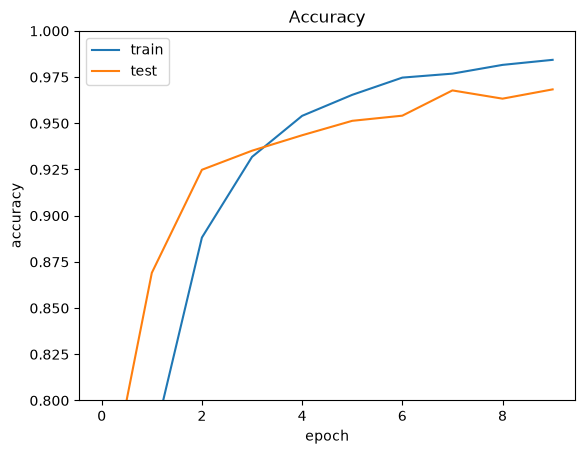

In [12]:
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.ylim(0.80, 1)
plt.title("Accuracy")
plt.xlabel('epoch')
plt.ylabel('accuracy')
plt.legend(['train','test'])
plt.show()

# Probando la NN

In [13]:
predictions = model.predict(x_test)
y_hat = np.argmax(predictions,axis=1)

225/225 [==============================] - 2s 7ms/step


In [14]:
errores = x_test[y_test != y_hat]
print("Elementos de prueba: {}".format(y_test.shape[0]))
errores_count = errores.shape[0]
errores_count
print("Errores identificados: {}".format(errores_count))
porcentaje_error = ((y_test != y_hat).sum() * 100) / y_test.shape[0]
print("Porcentaje de error: {} %".format(porcentaje_error))

Elementos de prueba: 7172
Errores identificados: 227
Porcentaje de error: 3.165086447295036 %


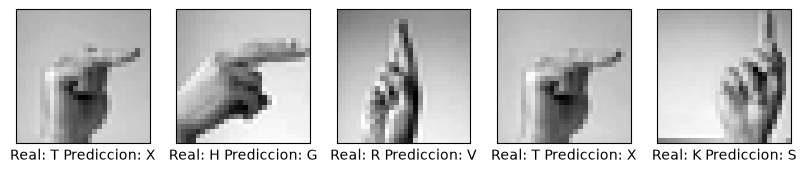

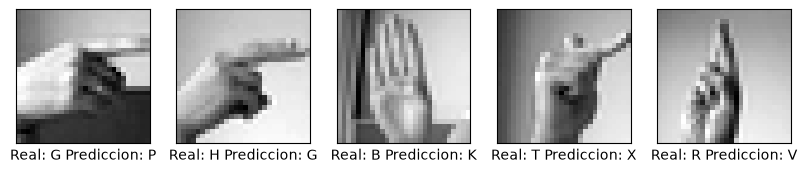

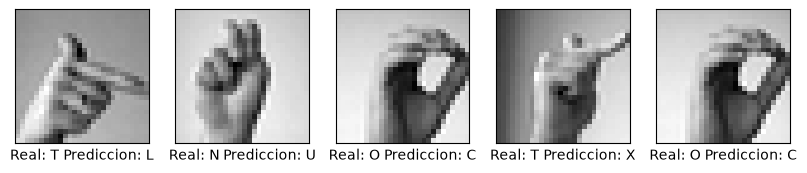

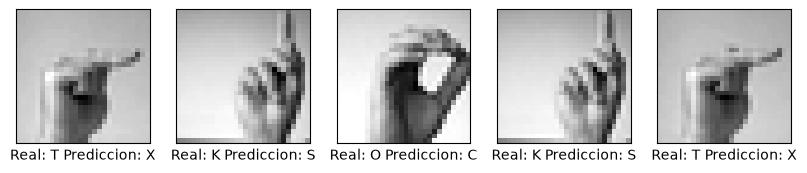

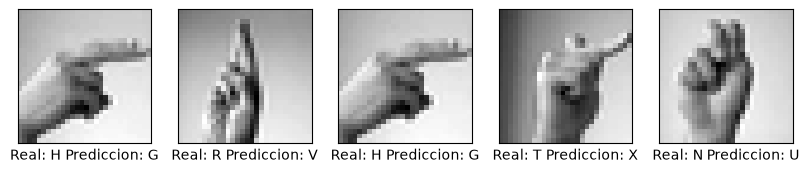

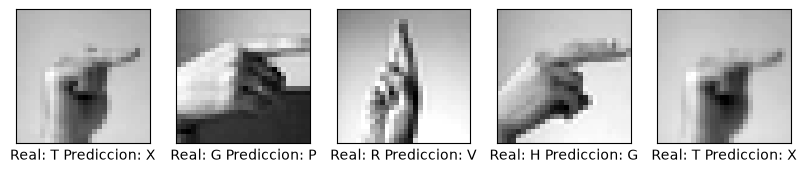

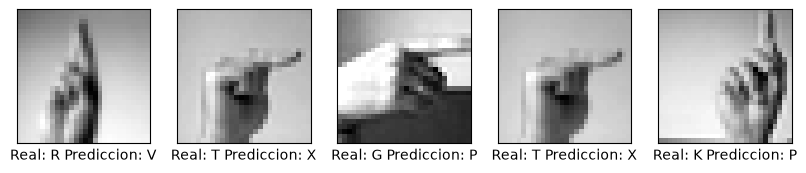

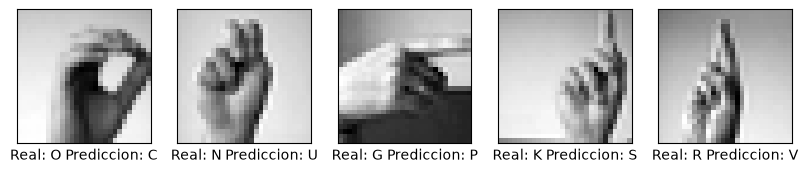

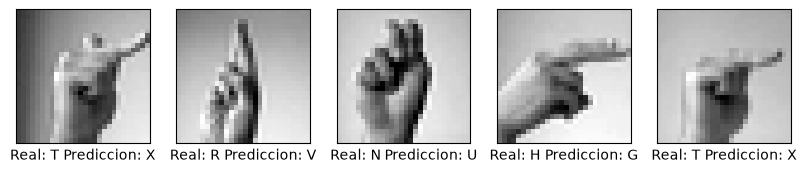

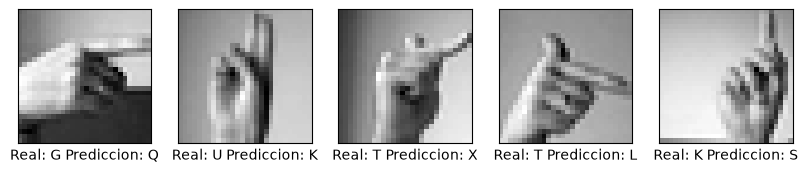

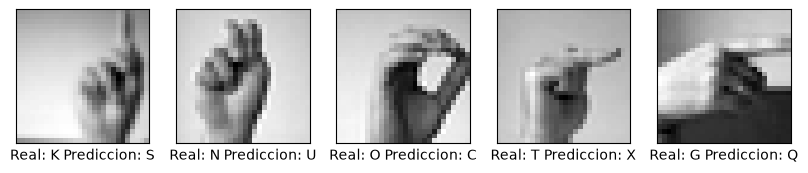

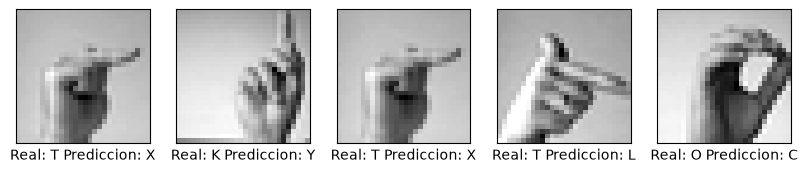

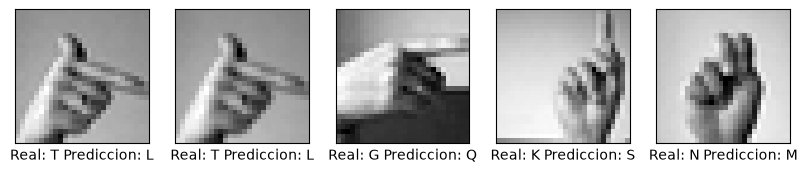

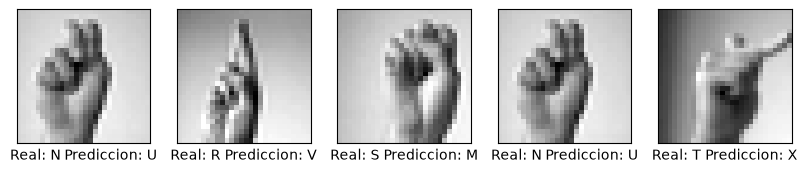

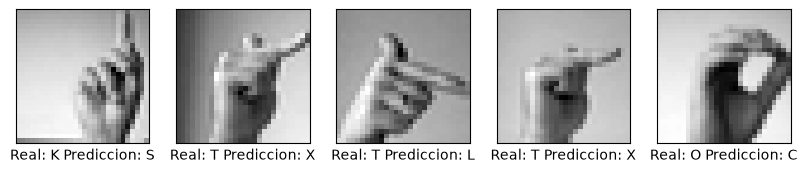

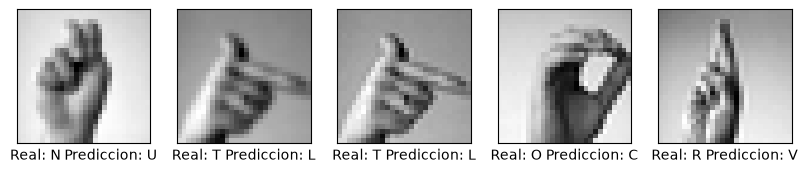

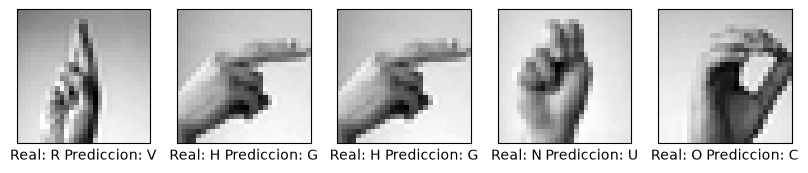

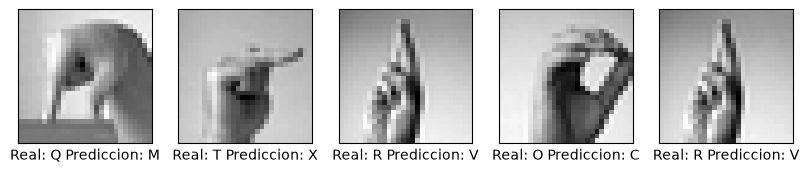

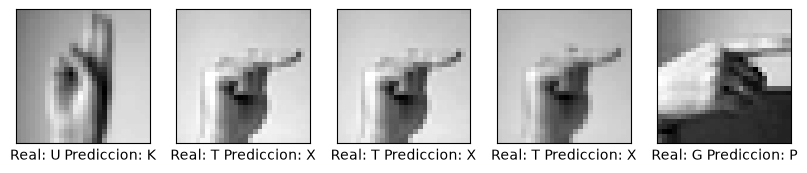

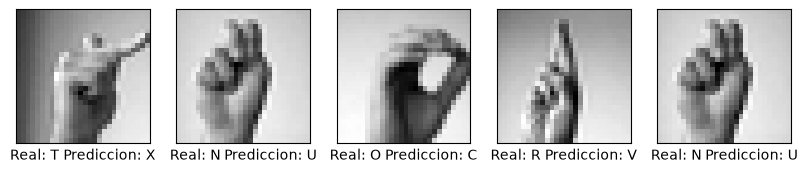

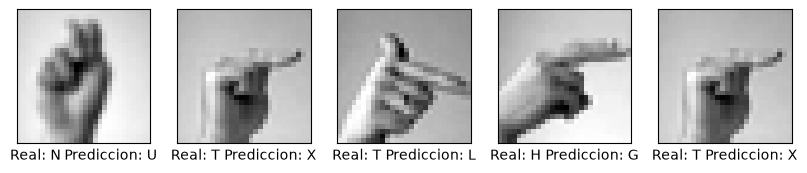

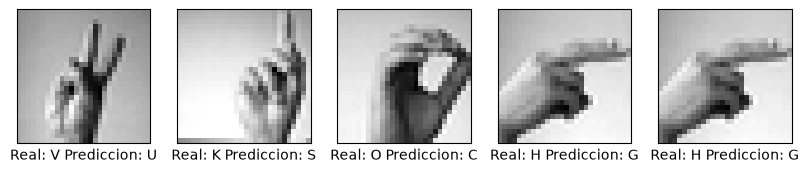

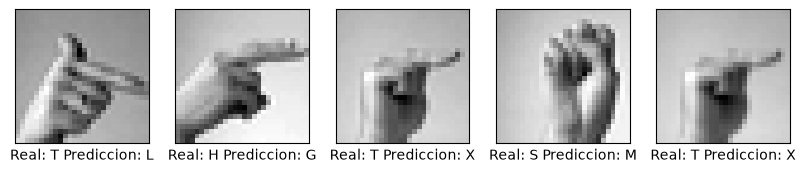

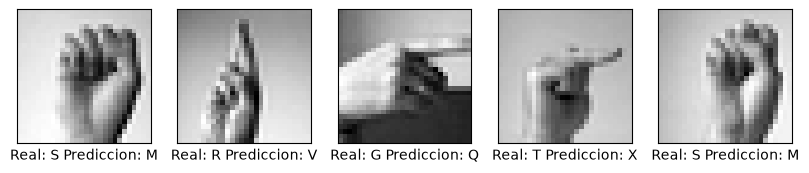

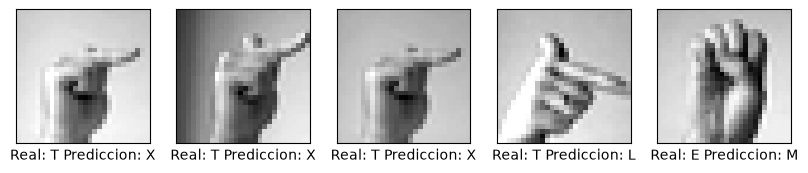

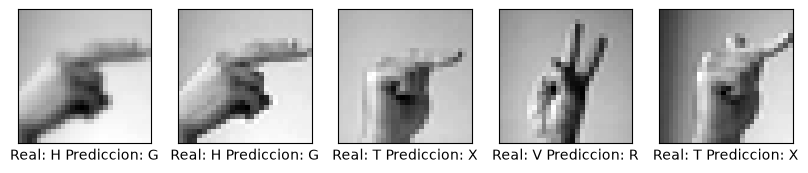

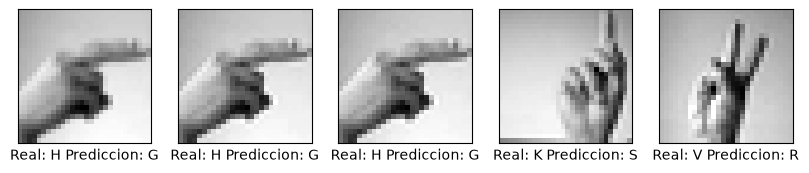

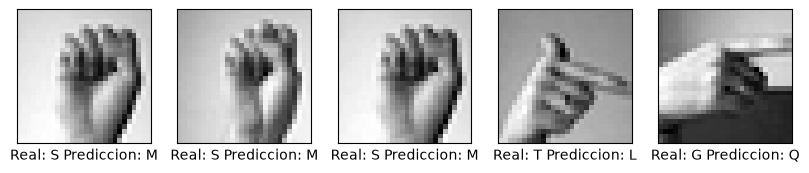

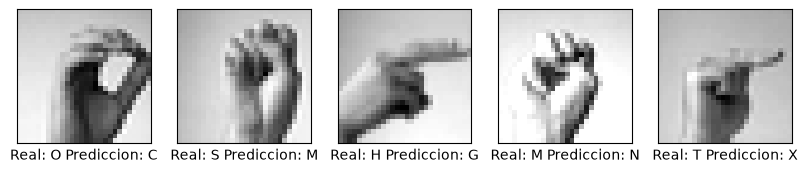

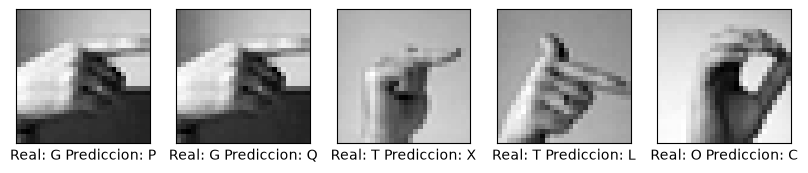

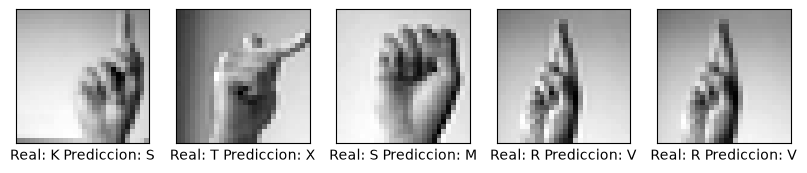

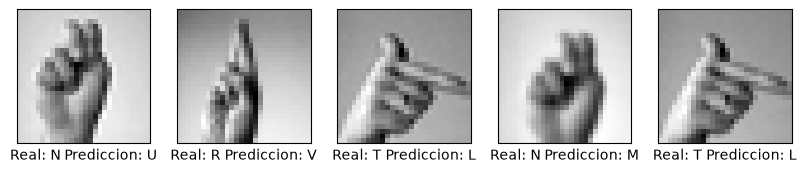

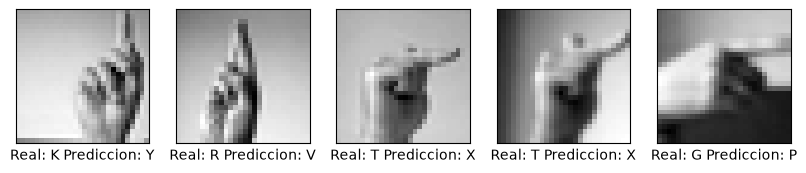

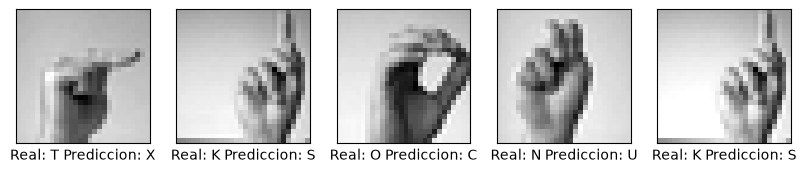

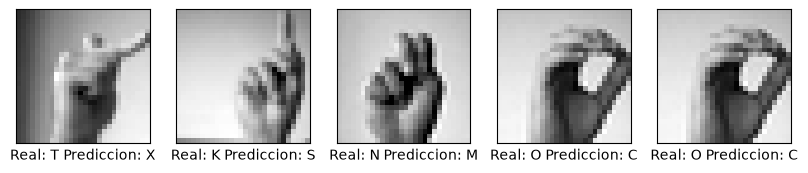

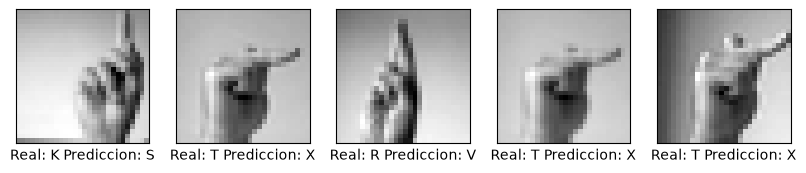

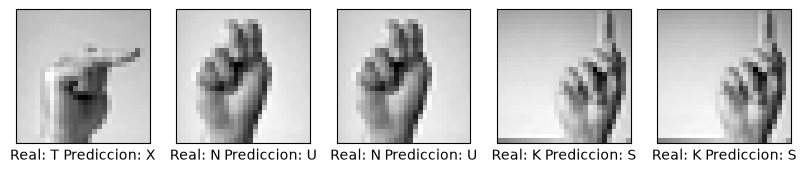

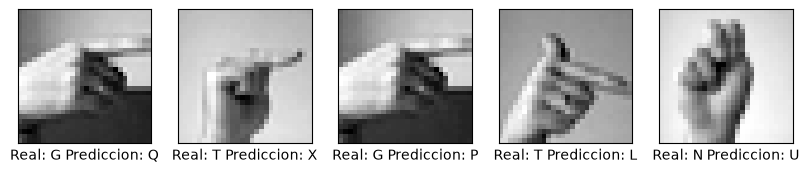

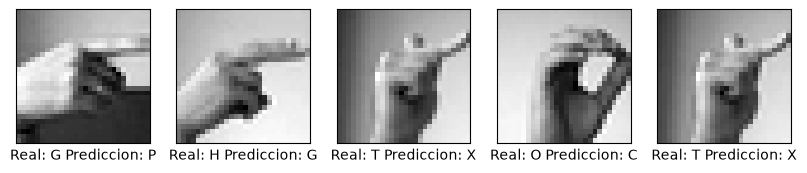

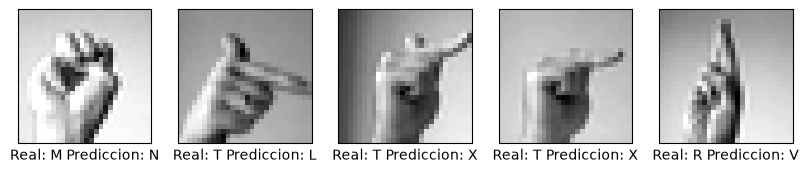

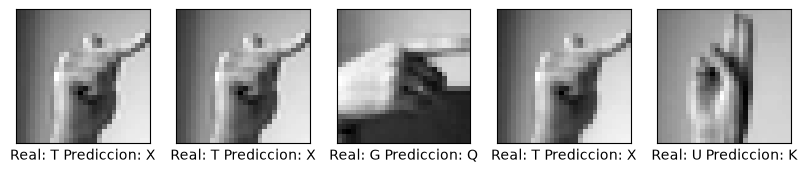

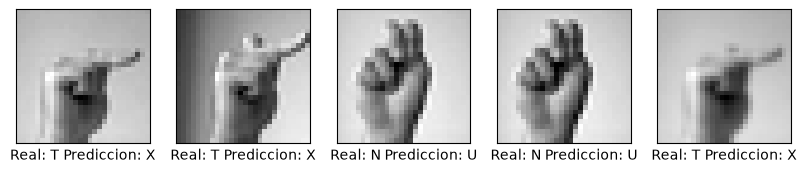

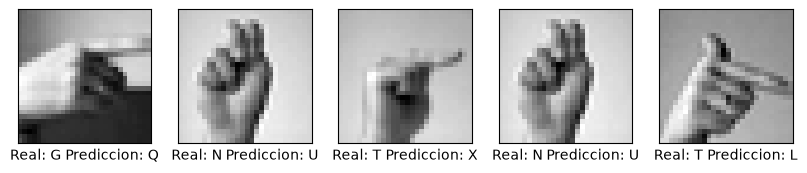

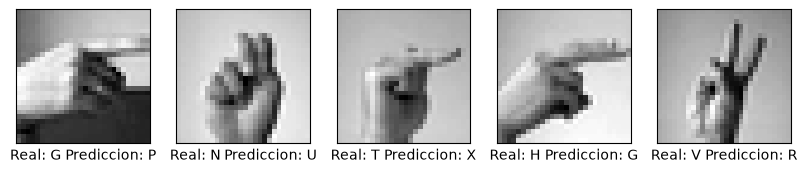

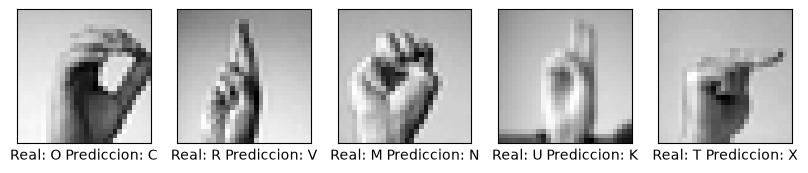

In [15]:
errores = x_test[y_test != y_hat]
real_labels = y_test[y_test != y_hat]
predicted_labels = y_hat[y_test != y_hat]

for j in range(round(errores.shape[0]/5)):
    plt.figure(figsize=(10,10))
    for i in range(min(5,errores_count-5*j)):
        plt.subplot(1,min(5,errores_count-5*j),i+1)
        plt.xticks([])
        plt.yticks([])
        plt.grid(False)
        number = errores[5*j+i].reshape(28,28)
        plt.imshow(number, cmap=plt.cm.gray)
        plt.xlabel("Real: {} Prediccion: {}".format
                   (abc[real_labels[5*j+i]],abc[predicted_labels[5*j+i]]))
    plt.show()

# Matriz de confusión

In [16]:
import seaborn as sns
from sklearn.metrics import confusion_matrix

In [17]:
mod_confusion_matrix = confusion_matrix(y_test, y_hat)
for i in range(24):
    mod_confusion_matrix[i][i] = 0

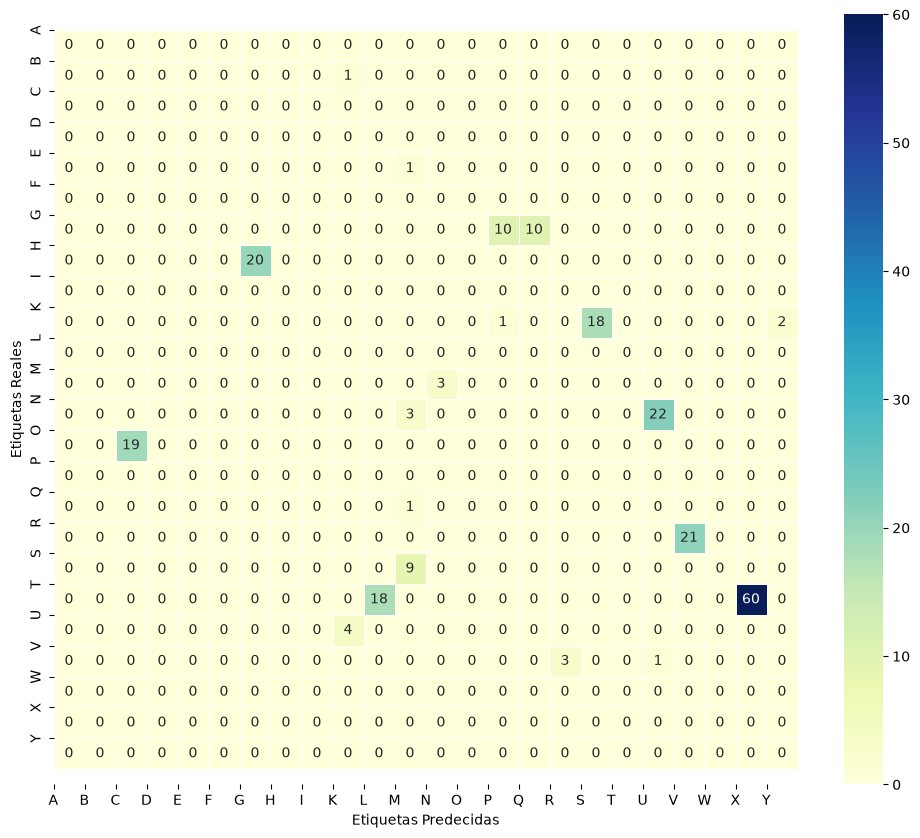

In [18]:
fig = plt.figure(figsize=(12,10))
ax = fig.add_subplot(1,1,1) 
sns.heatmap(mod_confusion_matrix, linewidth=0.5, annot=True, cmap="YlGnBu")
plt.xticks(np.arange(24), abc)
plt.yticks(np.arange(24), abc)
plt.ylabel("Etiquetas Reales")
plt.xlabel("Etiquetas Predecidas")
ax.set_ylim(24.5,-0.5);